In [4]:
#Load pandas and CSV file
import pandas as pd
daily_activity = pd.read_csv('/Users/sharonlim/Downloads/archive (2)/mturkfitbit_export_3.12.16-4.11.16/Fitabase Data 3.12.16-4.11.16/dailyActivity_merged.csv')

In [5]:
#Obtaining the first 5 rows of the daily_activity dataset
daily_activity.head()

,Id,ActivityDate,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories
0,1503960366,3/25/2016,11004,7.11,7.11,0.0,2.57,0.46,4.07,0.0,33,12,205,804,1819
1,1503960366,3/26/2016,17609,11.55,11.55,0.0,6.92,0.73,3.91,0.0,89,17,274,588,2154
2,1503960366,3/27/2016,12736,8.53,8.53,0.0,4.66,0.16,3.71,0.0,56,5,268,605,1944
3,1503960366,3/28/2016,13231,8.93,8.93,0.0,3.19,0.79,4.95,0.0,39,20,224,1080,1932
4,1503960366,3/29/2016,12041,7.85,7.85,0.0,2.16,1.09,4.61,0.0,28,28,243,763,1886


In [6]:
#Obtaining a summary of the daily_activity dataset structure
daily_activity.info()

<class 'pandas.DataFrame'>
RangeIndex: 457 entries, 0 to 456
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Id                        457 non-null    int64  
 1   ActivityDate              457 non-null    str    
 2   TotalSteps                457 non-null    int64  
 3   TotalDistance             457 non-null    float64
 4   TrackerDistance           457 non-null    float64
 5   LoggedActivitiesDistance  457 non-null    float64
 6   VeryActiveDistance        457 non-null    float64
 7   ModeratelyActiveDistance  457 non-null    float64
 8   LightActiveDistance       457 non-null    float64
 9   SedentaryActiveDistance   457 non-null    float64
 10  VeryActiveMinutes         457 non-null    int64  
 11  FairlyActiveMinutes       457 non-null    int64  
 12  LightlyActiveMinutes      457 non-null    int64  
 13  SedentaryMinutes          457 non-null    int64  
 14  Calories             

In [7]:
#Checking the total number of rows and columns in the daily_activity dataset
daily_activity.shape

(457, 15)

In [8]:
#Converting 'ActivityDate' column from a str data type to a date datatype
daily_activity['ActivityDate'] = pd.to_datetime(daily_activity['ActivityDate'])
#Checking
daily_activity.info()

<class 'pandas.DataFrame'>
RangeIndex: 457 entries, 0 to 456
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Id                        457 non-null    int64         
 1   ActivityDate              457 non-null    datetime64[us]
 2   TotalSteps                457 non-null    int64         
 3   TotalDistance             457 non-null    float64       
 4   TrackerDistance           457 non-null    float64       
 5   LoggedActivitiesDistance  457 non-null    float64       
 6   VeryActiveDistance        457 non-null    float64       
 7   ModeratelyActiveDistance  457 non-null    float64       
 8   LightActiveDistance       457 non-null    float64       
 9   SedentaryActiveDistance   457 non-null    float64       
 10  VeryActiveMinutes         457 non-null    int64         
 11  FairlyActiveMinutes       457 non-null    int64         
 12  LightlyActiveMinutes      457 non

In [9]:
#Creating a new column for days of the week
daily_activity['DayOfWeek'] = daily_activity['ActivityDate'].dt.day_name()
#Rearranging columns for easier visibility
cols = list(daily_activity.columns)
cols.insert(cols.index('ActivityDate') + 1, cols.pop(cols.index('DayOfWeek')))
daily_activity = daily_activity[cols]
#Confirming
daily_activity.head()

,Id,ActivityDate,DayOfWeek,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories
0,1503960366,2016-03-25,Friday,11004,7.11,7.11,0.0,2.57,0.46,4.07,0.0,33,12,205,804,1819
1,1503960366,2016-03-26,Saturday,17609,11.55,11.55,0.0,6.92,0.73,3.91,0.0,89,17,274,588,2154
2,1503960366,2016-03-27,Sunday,12736,8.53,8.53,0.0,4.66,0.16,3.71,0.0,56,5,268,605,1944
3,1503960366,2016-03-28,Monday,13231,8.93,8.93,0.0,3.19,0.79,4.95,0.0,39,20,224,1080,1932
4,1503960366,2016-03-29,Tuesday,12041,7.85,7.85,0.0,2.16,1.09,4.61,0.0,28,28,243,763,1886


In [10]:
#Analysing user activity (steps taken, activity intensity(mins), calories burned)

#Total steps taken on average per day of the week
day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
total_steps_avg = daily_activity.groupby('DayOfWeek')['TotalSteps'].mean()
total_steps_avg =  total_steps_avg.reindex(day_order)
total_steps_avg

DayOfWeek
Monday       7118.588235
Tuesday      4914.917808
Wednesday    7510.708333
Thursday     6847.083333
Friday       6737.561644
Saturday     7089.773333
Sunday       6058.013889
Name: TotalSteps, dtype: float64

<function matplotlib.pyplot.show(close=None, block=None)>

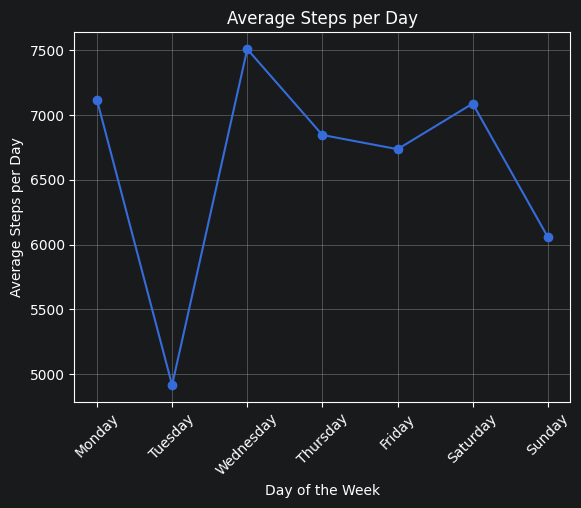

In [11]:
#Plotting line graph (average steps)
import matplotlib.pyplot as plt

total_steps_avg = daily_activity.groupby('DayOfWeek')['TotalSteps'].mean()
total_steps_avg =  total_steps_avg.reindex(day_order)
total_steps_avg.plot(kind='line', marker='o')
plt.title('Average Steps per Day')
plt.xlabel('Day of the Week')
plt.ylabel('Average Steps per Day')
plt.xticks(rotation=45)
plt.grid(True)
plt.show

In [12]:
#Total calories burned on average per day of the week
day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
calories_burned = daily_activity.groupby('DayOfWeek')['Calories'].mean()
calories_burned = calories_burned.reindex(day_order)
calories_burned

DayOfWeek
Monday       2252.867647
Tuesday      1742.424658
Wednesday    2377.458333
Thursday     2297.812500
Friday       2313.547945
Saturday     2277.586667
Sunday       2167.597222
Name: Calories, dtype: float64

<function matplotlib.pyplot.show(close=None, block=None)>

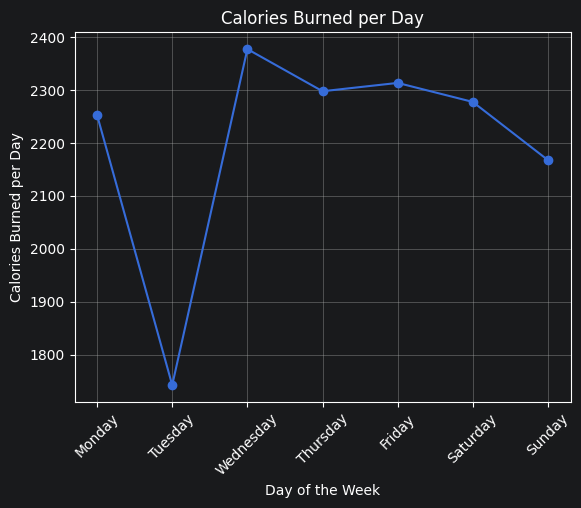

In [13]:
#Plotting line graph (calories burned)
import matplotlib.pyplot as plt

calories_burned = daily_activity.groupby('DayOfWeek')['Calories'].mean()
calories_burned = calories_burned.reindex(day_order)
calories_burned.plot(kind='line', marker='o')
plt.title('Calories Burned per Day')
plt.xlabel('Day of the Week')
plt.ylabel('Calories Burned per Day')
plt.xticks(rotation=45)
plt.grid(True)
plt.show

In [14]:
#Total minutes on average per exercise intensity
day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
activity_per_day = daily_activity.groupby('DayOfWeek').agg({'VeryActiveMinutes': 'mean', 'FairlyActiveMinutes': 'mean', 'LightlyActiveMinutes': 'mean', 'SedentaryMinutes': 'mean'})
activity_per_day = activity_per_day.reindex(day_order)
activity_per_day

,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes
DayOfWeek,,,,
Monday,18.955882,10.397059,171.647059,1032.852941
Tuesday,13.150685,8.835616,135.013699,850.246575
Wednesday,16.979167,14.520833,190.125000,1011.062500
Thursday,17.437500,14.479167,167.270833,1055.062500
Friday,16.000000,22.219178,178.219178,1054.712329
Saturday,18.973333,12.586667,190.026667,976.626667
Sunday,15.347222,9.208333,163.569444,1015.652778


In [30]:
activity_per_day['ModerateActivity'] = (activity_per_day['VeryActiveMinutes'] + activity_per_day['FairlyActiveMinutes'])
activity_per_day['ModerateActivity'].mean() * 7

np.float64(209.0906428507476)

<Axes: xlabel='DayOfWeek'>

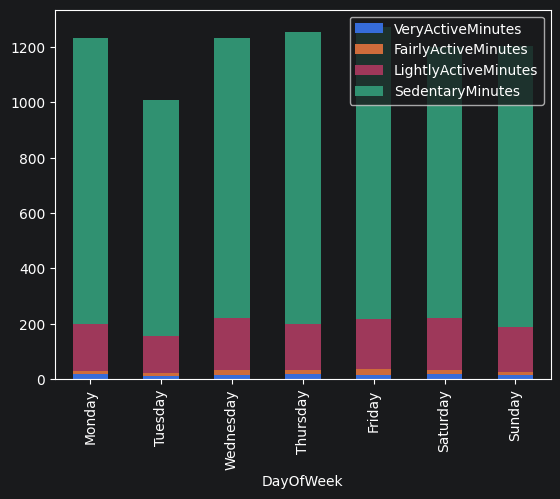

In [16]:
#Comparing proportion of time of total active minutes vs. sedentary minutes
activity_per_day['TotalActiveMinutes'] = (activity_per_day['VeryActiveMinutes'] + activity_per_day['FairlyActiveMinutes'] + activity_per_day['LightlyActiveMinutes'] + activity_per_day['SedentaryMinutes'])

activity_per_day[['VeryActiveMinutes', 'FairlyActiveMinutes', 'LightlyActiveMinutes', 'SedentaryMinutes']].plot(kind='bar', stacked = True)

In [17]:
#Load dataset containing sleep data
sleep = pd.read_csv('/Users/sharonlim/Downloads/archive (2)/mturkfitbit_export_3.12.16-4.11.16/Fitabase Data 3.12.16-4.11.16/minuteSleep_merged.csv')
sleep.head()
sleep.shape
sleep.info()
#Convert date to date time datatype
sleep['date'] = pd.to_datetime(sleep['date'])
sleep.info()
#Understanding what the value column means
sleep['value'].value_counts()

<class 'pandas.DataFrame'>
RangeIndex: 198559 entries, 0 to 198558
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype
---  ------  --------------   -----
 0   Id      198559 non-null  int64
 1   date    198559 non-null  str  
 2   value   198559 non-null  int64
 3   logId   198559 non-null  int64
dtypes: int64(3), str(1)
memory usage: 6.1 MB
<class 'pandas.DataFrame'>
RangeIndex: 198559 entries, 0 to 198558
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   Id      198559 non-null  int64         
 1   date    198559 non-null  datetime64[us]
 2   value   198559 non-null  int64         
 3   logId   198559 non-null  int64         
dtypes: datetime64[us](1), int64(3)
memory usage: 6.1 MB


value
1    183526
2     13010
3      2023
Name: count, dtype: int64

In [18]:
#Merging sleep data with daily activity data
merged = pd.merge(daily_activity, sleep , on=['Id'])
merged.head()
#Looking for correlation between activity level and sleep
daily_activity['TotalSteps'].corr(sleep['value']) #Very weak/no correlation
daily_activity['VeryActiveMinutes'].corr(sleep['value'])
daily_activity['SedentaryMinutes'].corr(sleep['value'])

np.float64(-0.10445961568653293)